# Етап 2: Deep Learning (ResNet-18)

Задача: Класифікація 27 стилів живопису за допомогою Transfer Learning на базі ResNet-18.

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import Dataset, DataLoader

import time
import tracemalloc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from datasets import load_dataset
from sklearn.metrics import (
    accuracy_score, top_k_accuracy_score, f1_score,
    balanced_accuracy_score, confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [4]:
import zipfile
import os

zip_path = "archive.zip" 
extract_dir = "./data"

if not os.path.exists(extract_dir):
    print(f"Розпакування {zip_path} у {extract_dir}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)
    print("Розпакування завершено")
else:
    print(f"Папка {extract_dir} вже існує, розпакування пропущено.")

Розпакування archive.zip у ./data...
Розпакування завершено


## Підготовка даних та трансформації

In [5]:
import os
import torch
import torchvision.transforms as T
import torchvision.datasets as datasets
from torch.utils.data import DataLoader, random_split

IMG_SIZE = 224

train_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

dataset_dir = extract_dir
subdirs = [os.path.join(dataset_dir, d) for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
if len(subdirs) == 1 and not any(os.path.isdir(os.path.join(subdirs[0], sub)) for sub in os.listdir(subdirs[0]) if os.path.isdir(os.path.join(subdirs[0], sub))):
    dataset_dir = subdirs[0]

full_dataset = datasets.ImageFolder(root=dataset_dir, transform=train_transform)
num_classes = len(full_dataset.classes)

train_size = int(0.85 * len(full_dataset))
val_size = len(full_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_dataset, 
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

val_dataset.dataset.transform = val_transform

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True, 
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    num_workers=2,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"Знайдено класів (стилів): {num_classes}")
print(f"Train: {len(train_dataset)} зображень, {len(train_loader)} батчів")
print(f"Val:   {len(val_dataset)} зображень, {len(val_loader)} батчів")

Знайдено класів (стилів): 27
Train: 69227 зображень, 2164 батчів
Val:   12217 зображень, 382 батчів


## Архітектура моделі (Transfer Learning ResNet-18)

Заморожуємо всі шари крім `layer4` та голови класифікатора.
Це дозволяє fine-tune тільки верхній блок + нову голову на 27 класів.

In [6]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

num_ftrs = model.fc.in_features
model.fc = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_ftrs, num_classes)
)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Модель ResNet-18 підготовлена")
print(f"Всього параметрів: {total_params:,}")
print(f"Навчаються: {trainable_params:,} ({100*trainable_params/total_params:.1f}%)")

Модель ResNet-18 підготовлена
Всього параметрів: 11,190,363
Навчаються: 8,407,579 (75.1%)


In [7]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-2
)

## Навчання та оцінка

In [8]:
def train_epoch(model, data_loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(data_loader, desc="Training")
    for inputs, targets in pbar:
        inputs, targets = inputs.to(device), targets.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()
        
        pbar.set_postfix({
            'loss': round(running_loss / total, 4),
            'acc': round(100. * correct / total, 2)
        })
        
    return running_loss / total, 100. * correct / total


def evaluate(model, data_loader):
    model.eval()
    all_preds, all_targets, all_probs = [], [], []
    
    with torch.no_grad():
        for inputs, targets in tqdm(data_loader, desc="Evaluating"):
            inputs = inputs.to(device)
            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            _, preds = torch.max(outputs, 1)
            
            all_probs.append(probs.cpu().numpy())
            all_preds.append(preds.cpu().numpy())
            all_targets.append(targets.numpy())
            
    all_probs = np.vstack(all_probs)
    all_preds = np.concatenate(all_preds)
    all_targets = np.concatenate(all_targets)
    
    top1 = accuracy_score(all_targets, all_preds) * 100
    top3 = top_k_accuracy_score(all_targets, all_probs, k=3, labels=list(range(27))) * 100
    macro_f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
    bal_acc = balanced_accuracy_score(all_targets, all_preds) * 100
    
    return top1, top3, macro_f1, bal_acc, all_targets, all_preds

In [10]:
NUM_EPOCHS = 3

tracemalloc.start()
t_start = time.time()

for epoch in range(NUM_EPOCHS):
    print(f"\n=== Епоха {epoch+1}/{NUM_EPOCHS} ===")
    
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    print(f"Train | Loss: {train_loss:.4f} | Acc: {train_acc:.2f}%")
    
    top1, top3, macro_f1, bal_acc, y_true, y_pred = evaluate(model, val_loader)
    print(f"Val   | Top-1: {top1:.2f}% | Top-3: {top3:.2f}% | Macro F1: {macro_f1:.4f} | Balanced Acc: {bal_acc:.2f}%")

train_time_sec = time.time() - t_start
_, peak_bytes = tracemalloc.get_traced_memory()
tracemalloc.stop()
ram_peak_mb = peak_bytes / (1024 * 1024)

print(f"\n--- Ресурси ---")
print(f"Загальний час навчання: {train_time_sec:.1f} сек ({train_time_sec/60:.1f} хв)")
print(f"Пік RAM: {ram_peak_mb:.1f} MB")


=== Епоха 1/3 ===


Training: 100%|██████████| 2164/2164 [21:31<00:00,  1.68it/s, loss=1.33, acc=55.6]


Train | Loss: 1.3343 | Acc: 55.65%


Evaluating: 100%|██████████| 382/382 [03:56<00:00,  1.61it/s]


Val   | Top-1: 57.03% | Top-3: 84.95% | Macro F1: 0.5405 | Balanced Acc: 51.57%

=== Епоха 2/3 ===


...

Val   | Top-1: 58.25% | Top-3: 85.25% | Macro F1: 0.5498 | Balanced Acc: 53.84%

=== Епоха 3/3 ===


Training: 100%|██████████| 2164/2164 [21:30<00:00,  1.68it/s, loss=0.659, acc=78.1]


Train | Loss: 0.6593 | Acc: 78.12%


Evaluating: 100%|██████████| 382/382 [03:52<00:00,  1.64it/s]

Val   | Top-1: 58.15% | Top-3: 85.36% | Macro F1: 0.5673 | Balanced Acc: 53.75%

--- Ресурси ---
Загальний час навчання: 4608.4 сек (76.8 хв)
Пік RAM: 20.2 MB


## Фінальні результати та матриця помилок

In [11]:
print(f"Фінальні результати ResNet-18 (Deep Learning):")
print(f"  Top-1 Accuracy:    {top1:.2f}%")
print(f"  Top-3 Accuracy:    {top3:.2f}%")
print(f"  Macro F1:          {macro_f1:.4f}")
print(f"  Balanced Accuracy: {bal_acc:.2f}%")
print(f"  Час навчання:      {train_time_sec:.1f} сек")
print(f"  Пік RAM:           {ram_peak_mb:.1f} MB")

model_path = 'resnet18_wikiart.pth'
torch.save(model.state_dict(), model_path)
import os
model_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"  Розмір моделі:     {model_size_mb:.2f} MB")

Фінальні результати ResNet-18 (Deep Learning):
  Top-1 Accuracy:    58.15%
  Top-3 Accuracy:    85.36%
  Macro F1:          0.5673
  Balanced Accuracy: 53.75%
  Час навчання:      4608.4 сек
  Пік RAM:           20.2 MB
  Розмір моделі:     42.76 MB


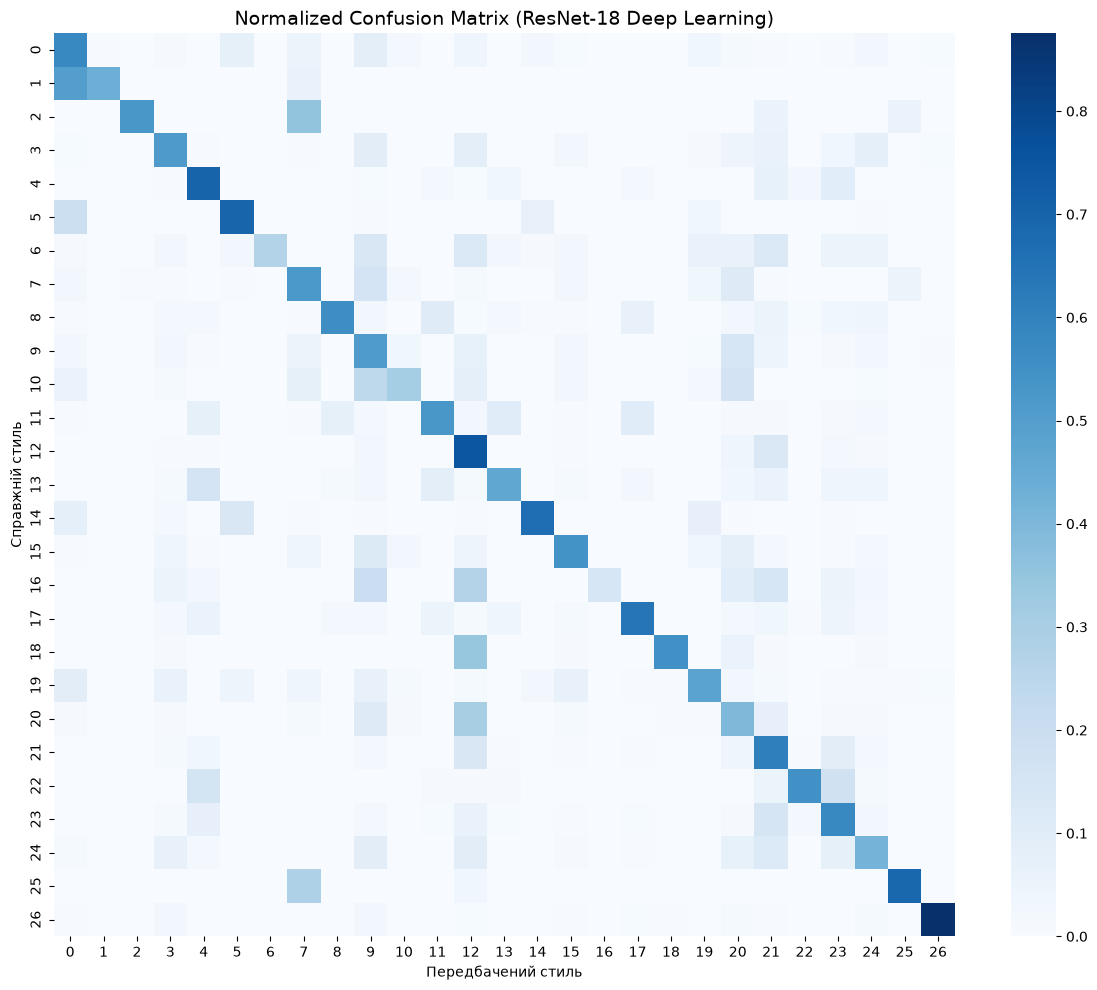

In [12]:
cm = confusion_matrix(y_true, y_pred, normalize='true')

plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap='Blues', annot=False)
plt.title('Normalized Confusion Matrix (ResNet-18 Deep Learning)', fontsize=14)
plt.xlabel('Передбачений стиль')
plt.ylabel('Справжній стиль')
plt.tight_layout()
plt.savefig('confusion_matrix_dl.png', dpi=150)
plt.show()

In [13]:
import pandas as pd
import time
import os
import torch

model.eval()
sample_batch, _ = next(iter(val_loader))
sample_batch = sample_batch.to(device)

with torch.no_grad():
    _ = model(sample_batch)

t_lat = time.perf_counter()
with torch.no_grad():
    _ = model(sample_batch)
inference_ms = ((time.perf_counter() - t_lat) * 1000.0) / len(sample_batch)

print(f"Швидкість інференсу: {inference_ms:.4f} мс / зразок")

m2_metrics = {
    'Model': 'ResNet-18 (Deep Learning)',
    'Top1_Acc_%': round(top1, 2),
    'Top3_Acc_%': round(top3, 2),
    'Macro_F1': round(macro_f1, 4),
    'Balanced_Acc_%': round(bal_acc, 2),
    'Train_Time_s': round(train_time_sec, 2),
    'Inference_ms': round(inference_ms, 4),
    'RAM_Peak_MB': round(ram_peak_mb, 2),
    'Model_Size_MB': round(model_size_mb, 2)
}

df_m2 = pd.DataFrame([m2_metrics])
df_m2.to_csv('benchmark_results_resnet18.csv', index=False)

if os.path.exists('benchmark_results_val.csv'):
    df_m1 = pd.read_csv('benchmark_results_val.csv')
    combined_df = pd.concat([df_m1, df_m2], ignore_index=True)
    combined_df.to_csv('final_models_benchmark_comparison.csv', index=False)
    print("\n=== Зведені результати всіх моделей ===")
    display(combined_df)
else:
    print("\n=== Результати ResNet-18 ===")
    display(df_m2)

Швидкість інференсу: 0.1074 мс / зразок

=== Зведені результати всіх моделей ===


,Model,Top1_Acc_%,Top3_Acc_%,Macro_F1,Balanced_Acc_%,Train_Time_s,Inference_ms,RAM_Peak_MB,Model_Size_MB
0,"SGD (Balanced, PCA-128)",19.01,39.25,0.1040,16.10,5.42,0.0008,2911.79,0.03
1,"Logistic Regression (Unweighted, PCA-128)",26.91,52.51,0.1071,11.15,9.25,0.0006,25.37,0.03
2,"Logistic Regression (Smoothed, PCA-128)",27.61,53.30,0.1339,14.02,4.39,0.0007,25.80,0.03
3,"HistGradientBoosting (Balanced, PCA-128)",26.29,52.11,0.2129,24.83,74.31,0.0290,111.47,1.77
4,"Tuned HistGradientBoosting (Full 651, Smoothed)",38.18,65.99,0.3071,29.29,559.35,0.0924,556.88,5.98
5,"ExtraTrees Classifier (Full 651, Balanced)",31.05,57.12,0.2493,30.44,25.65,0.0475,164.09,151.27
6,Ensemble (GBDT 40% + ET 60%),38.59,66.12,0.3120,31.08,585.00,0.1399,556.88,157.25
7,ResNet-18 (Deep Learning),58.15,85.36,0.5673,53.75,4608.43,0.1074,20.16,42.76
